<a href="https://colab.research.google.com/github/drishtikatgeri/numpy-image-pixel-manipulator/blob/main/Untitled5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Pixel Manipulator (NumPy)

Basically an image is just a grid of numbers, so I'm using NumPy to edit one. I made an Indian flag from scratch, then cropped it, flipped it, played with the colours and brightness, and checked how much memory it takes. No loops, only NumPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

(200, 300, 3) uint8


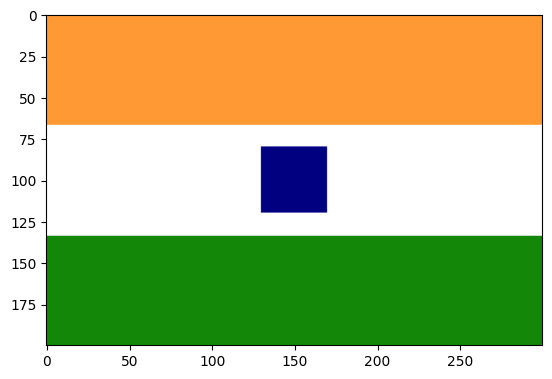

In [2]:
saffron = np.full((67, 300, 3), (255, 153, 51), dtype=np.uint8)
white   = np.full((67, 300, 3), (255, 255, 255), dtype=np.uint8)
green   = np.full((66, 300, 3), (19, 136, 8), dtype=np.uint8)

flag = np.zeros((200, 300, 3), dtype=np.uint8)
flag[0:67]    = saffron
flag[67:134]  = white
flag[134:200] = green
flag[80:120, 130:170] = [0, 0, 128]   # blue square in the middle (the chakra)

print(flag.shape, flag.dtype)
plt.imshow(flag)
plt.show()

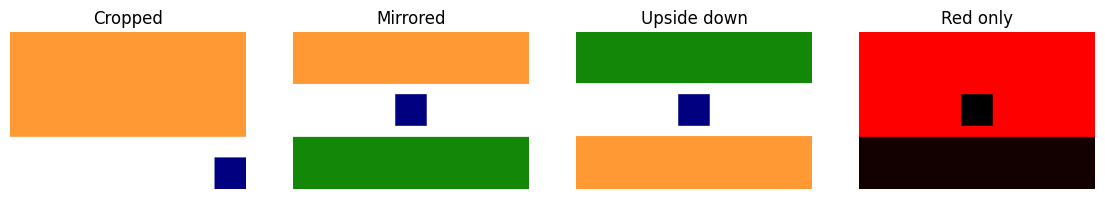

In [3]:
cropped  = flag[0:100, 0:150]        # top-left part
flip_lr  = flag[:, ::-1]             # mirror left-right
flip_ud  = flag[::-1]                # upside down

red_only = np.zeros_like(flag)
red_only[:, :, 0] = flag[:, :, 0]    # keep only the red channel

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, im, t in zip(ax, [cropped, flip_lr, flip_ud, red_only],
                    ["Cropped", "Mirrored", "Upside down", "Red only"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.show()

Bright pixels: 18500


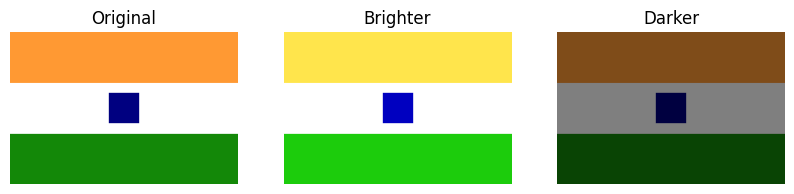

In [4]:
bright = (flag.astype(np.float32) * 1.5).clip(0, 255).astype(np.uint8)
dark   = (flag.astype(np.float32) * 0.5).astype(np.uint8)

gray = flag.mean(axis=2)
bright_mask = gray > 200
print("Bright pixels:", bright_mask.sum())

fig, ax = plt.subplots(1, 3, figsize=(10, 3))
for a, im, t in zip(ax, [flag, bright, dark], ["Original", "Brighter", "Darker"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.show()

In [5]:
img8  = flag.copy()
img64 = flag.astype(np.float64)
print("uint8   :", img8.nbytes, "bytes")
print("float64 :", img64.nbytes, "bytes")
print("Ratio   :", img64.nbytes / img8.nbytes)

uint8   : 180000 bytes
float64 : 1440000 bytes
Ratio   : 8.0


## Conclusion
- an image is a 3D array (height, width, colour)
- slicing can do crop/flip with no loops
- uint8 overflows if you do maths on it directly
- uint8 is 8x smaller than float64
